# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

## 1. Introduction  

The objective of this project is to investigate and compare machine learning models for predicting a quantitative measure of diabetes disease progression one year after baseline.

The project uses the Diabetes dataset provided by Scikit-Learn. Different regression models will be evaluated using the training, validation, and test datasets. The evaluation metrics are R-squared, Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

The purpose is to identify models that predict the target accurately, generalize to unseen observations, and have limitations that are clearly understood.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Load the dataset
diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

# Combine features and target for EDA
df = X.copy()
df["disease_progression"] = y

print("Dataset shape:", df.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset description:")
print(diabetes.DESCR)

Dataset shape: (442, 11)

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First five rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Dataset description:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feat

## 2. Problem Framing

### Problem Statement

The objective of this project is to predict a quantitative measure of diabetes disease progression one year after baseline using patient characteristics collected at baseline. The dataset contains 442 observations and 10 predictor variables, including age, sex, body mass index (BMI), average blood pressure, and six blood-serum measurements.

This is a **supervised regression problem** because the target variable is continuous rather than a categorical label.

### Machine Learning Objective

The goal is to develop models that predict disease progression accurately and generalize to unseen data. The models will be compared using R-squared, Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

### Model Evaluation Considerations

R-squared measures how much of the variation in the target is explained by the model. MAE measures the average absolute prediction error in target units. MAPE expresses prediction errors as percentages, but it can be misleading when actual target values are close to zero.

Similar to the classification and K-Nearest Neighbors workshops, model evaluation should consider performance on unseen observations rather than relying only on training performance. More complex models may fit the training data well but perform poorly on new observations.

The dataset represents a disease-progression measure, not a direct diagnosis of diabetes. Therefore, the predictions should not be interpreted as a medical diagnosis or used as a clinical screening tool without further validation.

In [2]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Summary statistics
print("\nDescriptive statistics:")
display(df.describe().T)

Missing values per column:
age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
disease_progression    0
dtype: int64

Number of duplicate rows:
0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


## 4. Exploratory Data Analysis (EDA)

EDA examines the dataset's structure, distributions, and relationships between the predictors and `disease_progression`.

This section includes:
1. Descriptive statistics and missing-value/duplicate checks.
2. Histograms for all features and the target.
3. A BMI-versus-target scatter plot, plus scatter plots for other features that show relatively strong target correlations.
4. A correlation matrix.

The plots and statistics describe associations in this dataset; correlation does not establish causation. EDA is used to understand the data and guide model choices, not to inspect the test set for model tuning.

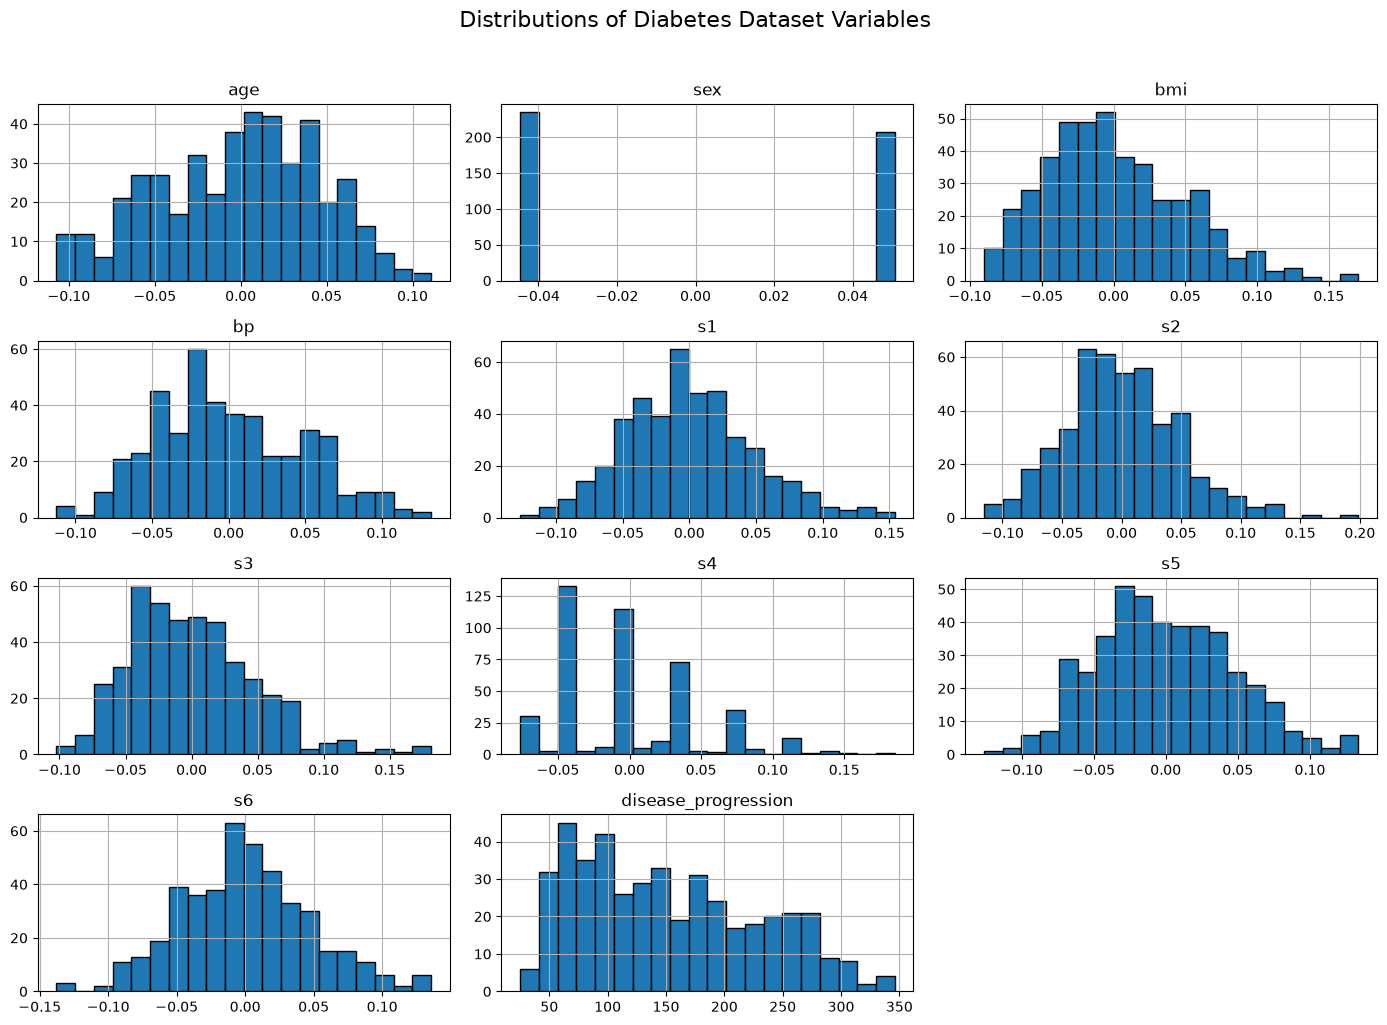

In [3]:
# Plot histograms for all features and the target variable
df.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Diabetes Dataset Variables",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

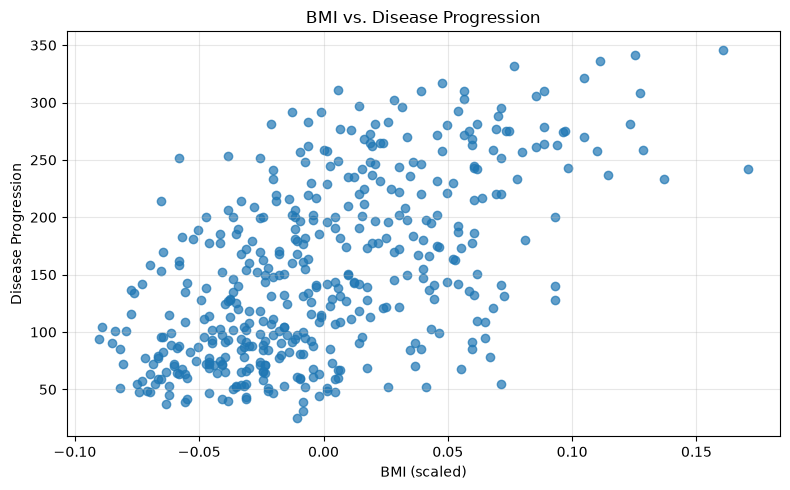

In [4]:
# Examine the relationship between BMI and disease progression
plt.figure(figsize=(8, 5))

plt.scatter(
    df["bmi"],
    df["disease_progression"],
    alpha=0.7
)

plt.title("BMI vs. Disease Progression")
plt.xlabel("BMI (scaled)")
plt.ylabel("Disease Progression")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.1 Additional feature-versus-target scatter plots

The correlation matrix is used to select a few additional features for visual inspection. These plots help show whether relationships with disease progression appear approximately linear, nonlinear, or highly variable. The feature selection is descriptive and does not imply causation.

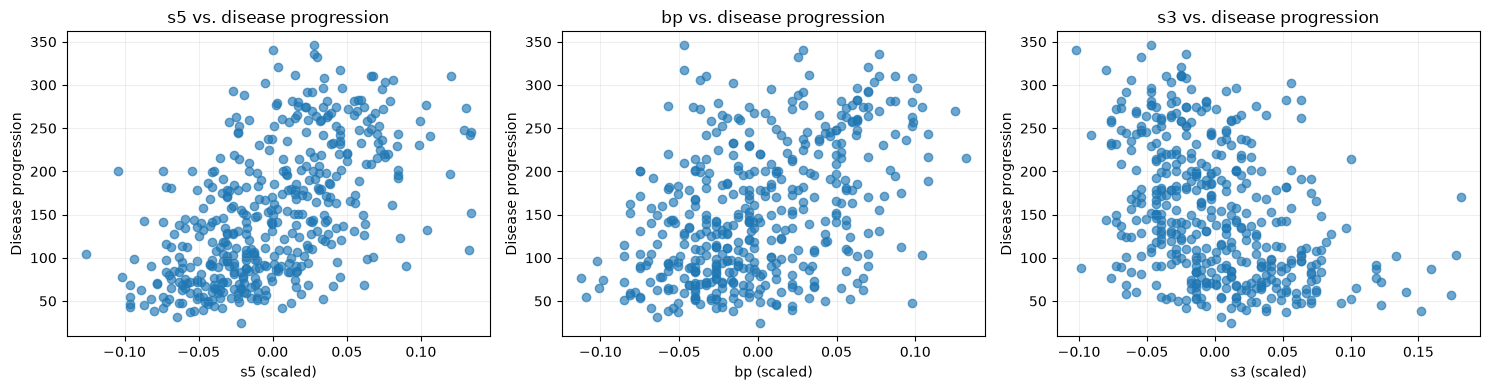

,Correlation with target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s3,-0.395
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043


In [5]:
# Inspect a few additional features with comparatively strong target correlations.
# The diabetes features are standardized/scaled in the supplied dataset.
features_to_plot = ["s5", "bp", "s3"]

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(15, 4))
for ax, feature in zip(axes, features_to_plot):
    ax.scatter(df[feature], df["disease_progression"], alpha=0.65)
    ax.set_title(f"{feature} vs. disease progression")
    ax.set_xlabel(f"{feature} (scaled)")
    ax.set_ylabel("Disease progression")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Report the correlations used to contextualize the plots.
target_correlations = (
    df.corr(numeric_only=True)["disease_progression"]
      .drop("disease_progression")
      .sort_values(key=lambda values: values.abs(), ascending=False)
)
display(target_correlations.rename("Correlation with target").to_frame().round(3))


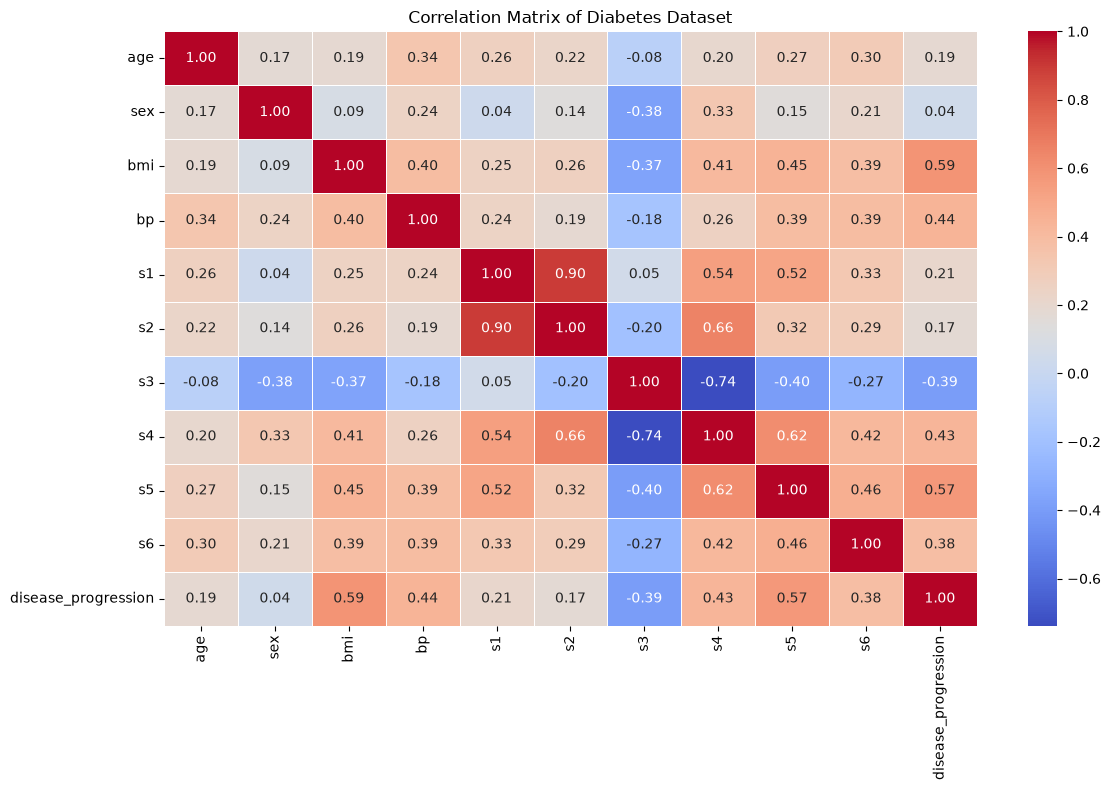

In [6]:
# Calculate correlations between all variables
correlation_matrix = df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Diabetes Dataset")
plt.tight_layout()
plt.show()

### 4.2 EDA Findings and Insights

**1. Distributions and data quality.** The histograms show variation in the scaled predictor values and in the target. The missing-value and duplicate checks are used to determine whether further cleaning is needed. Since the dataset is supplied as a curated Scikit-learn teaching dataset, do not remove rows or impute values unless the checks provide a reason.

**2. BMI and disease progression.** The BMI scatter plot shows a positive association overall, but observations with similar BMI values can have noticeably different progression values. BMI alone therefore cannot explain all target variation. Polynomial terms may represent curvature, but their value must be established using validation performance.

**3. Other features.** The additional scatter plots and target-correlation table allow comparison of `s5`, `bp`, and `s3` with the target. A stronger linear correlation can be useful evidence of association, but it does not guarantee better predictive performance in a multivariate model.

**4. Correlation matrix.** The correlation matrix summarizes pairwise linear associations among features and the target. Correlated predictors may contain overlapping information. Correlation is descriptive, not causal, and the model comparisons later in the notebook are needed to determine predictive usefulness.

### 5. Train, Validation, and Test Split

The dataset is divided into three subsets to develop and evaluate the machine learning models.

- **Training set (75%):** Used to fit the models.
- **Validation set (10%):** Used to compare models and select appropriate model configurations.
- **Test set (15%):** Reserved for the final evaluation of the selected model on unseen data.

A fixed random state is used to make the split reproducible. The test set will remain separate during model selection to reduce the risk of biased performance estimates.

In [7]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df.drop(columns=["disease_progression"])
y = df["disease_progression"]

# Step 1: Reserve 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42
)

# Step 2: Split the remaining 85% into 75% training and 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.10 / 0.85,
    random_state=42
)

# Display the split sizes
print("Training set:", X_train.shape, f"({len(X_train) / len(df):.1%})")
print("Validation set:", X_val.shape, f"({len(X_val) / len(df):.1%})")
print("Test set:", X_test.shape, f"({len(X_test) / len(df):.1%})")

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

Training set: (330, 10) (74.7%)
Validation set: (45, 10) (10.2%)
Test set: (67, 10) (15.2%)

Target shapes:
y_train: (330,)
y_val: (45,)
y_test: (67,)


# Part 2: Univariate Polynomial Regression

## 2.1. Building Polynomial Regression Models

In this section, six models will be developed to predict `disease_progression` using only the `bmi` feature. Polynomial regression will be used to investigate whether a linear or nonlinear relationship provides better predictions.

The models will use polynomial degrees from 0 to 5:

- **Degree 0:** A constant prediction based on the mean target value.
- **Degree 1:** A linear regression model.
- **Degrees 2–5:** Polynomial regression models that can represent increasingly complex relationships.

All models will be fitted using the training set. Their performance will be compared on both the training and validation sets using R-squared, Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). The validation results will guide model selection, while the test set will remain reserved for final evaluation.

### 2.1.1 Prepare the BMI data

In [8]:
# Select BMI as the only predictor
X_train_bmi = X_train[["bmi"]]
X_val_bmi = X_val[["bmi"]]
X_test_bmi = X_test[["bmi"]]

print("Training BMI shape:", X_train_bmi.shape)
print("Validation BMI shape:", X_val_bmi.shape)
print("Test BMI shape:", X_test_bmi.shape)

Training BMI shape: (330, 1)
Validation BMI shape: (45, 1)
Test BMI shape: (67, 1)


### 2.1.2 Fix six models

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

models = {}

for degree in range(6):

    if degree == 0:
        # Degree 0: predict the training-set mean
        model = DummyRegressor(strategy="mean")
    else:
        # Degrees 1 through 5: polynomial regression
        model = make_pipeline(
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            ),
            LinearRegression()
        )

    model.fit(X_train_bmi, y_train)
    models[degree] = model

print("All six models have been fitted successfully.")

All six models have been fitted successfully.


### 2.1.3 Compare training and validation performance

In [10]:
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

results = []

for degree, model in models.items():

    # Training predictions
    train_pred = model.predict(X_train_bmi)

    # Validation predictions
    val_pred = model.predict(X_val_bmi)

    results.append({
        "Degree": degree,
        "Train R2": r2_score(y_train, train_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Train MAPE (%)": (
            mean_absolute_percentage_error(y_train, train_pred) * 100
        ),
        "Validation R2": r2_score(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation MAPE (%)": (
            mean_absolute_percentage_error(y_val, val_pred) * 100
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Degree,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,0,0.000,66.548,63.352,-0.000,63.447,58.793
1,1,0.354,52.278,48.462,0.449,41.998,40.445
2,2,0.355,52.267,48.448,0.449,41.758,40.310
3,3,0.355,52.223,48.356,0.447,41.741,40.259
4,4,0.358,51.944,47.964,0.449,41.953,40.241
5,5,0.359,51.814,47.831,0.454,42.083,40.340


### 2.1.4. Model Comparison and Selection

The table above compares all six polynomial degrees using training and validation \(R^2\), MAE, and MAPE. Model selection is based on **validation MAE**, because it measures average absolute error in the target's units and is straightforward to interpret. The selected degree is calculated from the table in the next evaluation cell rather than hard-coded.

Training performance is useful for diagnosing fit, but it should not be the sole selection criterion. A much better training score than validation score can indicate overfitting. MAPE is reported because it is required by the assignment, but percentage errors can be disproportionately influenced by observations with smaller actual target values.

### 2.1.5 Evaluate the selected model on the test set

In [11]:
# Select the polynomial model with the lowest validation MAE.
# The validation set is used for model selection; the test set is reserved
# for one final evaluation after selection.
best_degree = int(
    results_df.loc[results_df["Validation MAE"].idxmin(), "Degree"]
)
best_model = models[best_degree]

# Generate predictions on the unseen test set
y_test_pred = best_model.predict(X_test_bmi)

# Calculate test metrics
test_r2 = r2_score(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mape = mean_absolute_percentage_error(y_test, y_test_pred) * 100

print("Selected polynomial degree (lowest validation MAE):", best_degree)
print(f"Test R-squared: {test_r2:.3f}")
print(f"Test MAE: {test_mae:.3f}")
print(f"Test MAPE: {test_mape:.2f}%")

Selected polynomial degree (lowest validation MAE): 3
Test R-squared: 0.207
Test MAE: 54.629
Test MAPE: 48.54%


### 2.1.6 Plot training, validation, and test observations

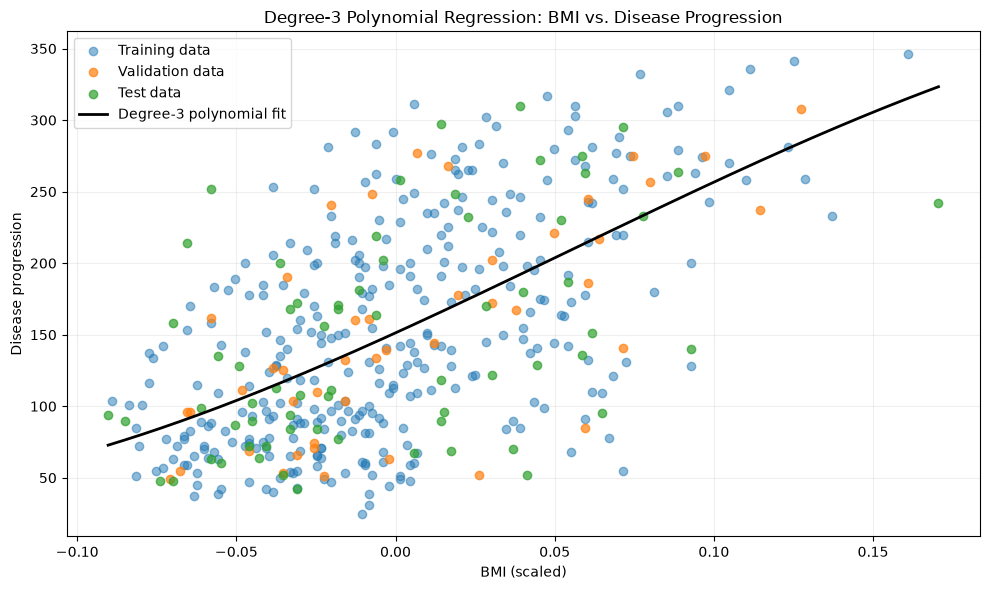

In [12]:
# Generate a smooth range of BMI values as a DataFrame so the column name
# matches the DataFrame used when fitting the pipeline.
bmi_range = pd.DataFrame({
    "bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 300)
})
progression_curve = best_model.predict(bmi_range)

plt.figure(figsize=(10, 6))
plt.scatter(X_train_bmi["bmi"], y_train, alpha=0.5, label="Training data")
plt.scatter(X_val_bmi["bmi"], y_val, alpha=0.7, label="Validation data")
plt.scatter(X_test_bmi["bmi"], y_test, alpha=0.7, label="Test data")
plt.plot(
    bmi_range["bmi"], progression_curve,
    color="black", linewidth=2,
    label=f"Degree-{best_degree} polynomial fit"
)
plt.title(f"Degree-{best_degree} Polynomial Regression: BMI vs. Disease Progression")
plt.xlabel("BMI (scaled)")
plt.ylabel("Disease progression")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2.1.7 Write Polynomial Equation

In [13]:
# The degree-0 model is a constant predictor and has no polynomial pipeline.
if best_degree == 0:
    intercept = float(best_model.constant_[0])
    print(f"Selected degree: 0 (constant model)")
    print(f"Equation: y_hat = {intercept:.2f}")
else:
    polynomial = best_model.named_steps["polynomialfeatures"]
    regression = best_model.named_steps["linearregression"]
    feature_names = polynomial.get_feature_names_out(["bmi"])
    coefficients = regression.coef_
    intercept = regression.intercept_

    equation_terms = [f"{intercept:.2f}"]
    for feature_name, coefficient in zip(feature_names, coefficients):
        equation_terms.append(f"({coefficient:.2f} × {feature_name})")

    print(f"Selected degree: {best_degree}")
    print("Feature names:", list(feature_names))
    print("Equation: y_hat = " + " + ".join(equation_terms))

Selected degree: 3
Feature names: ['bmi', 'bmi^2', 'bmi^3']
Equation: y_hat = 151.28 + (1012.43 × bmi) + (1028.74 × bmi^2) + (-6158.21 × bmi^3)


### Interpretation of Test Results

The validation table selected **degree 3** because it has the lowest validation MAE (41.741). On the held-out test set, the selected model achieved **R² = 0.207, MAE = 54.629, and MAPE = 48.54%**. The positive R² indicates that the model explains some target variation, but its test performance is weaker than its validation performance and the average absolute error remains substantial.

The BMI-only result is a useful baseline, not evidence that BMI alone is sufficient to predict progression accurately. Interpret the metrics together: R² describes explained variation relative to a mean baseline, MAE reports average absolute error in the target's units, and MAPE can be disproportionately affected by observations with smaller actual target values. The test set is reserved for final evaluation rather than repeated model tuning.

### Equation of the Selected Polynomial Model

The code cell above prints the fitted equation using the selected model's actual intercept and coefficients, rounded to two decimal places. The equation's degree follows the validation-MAE selection, so it remains correct if the selected degree changes when the notebook is rerun. The predictor \(x\) is the dataset's scaled BMI feature, not BMI in conventional clinical units.

### 2.1.8 Predict disease progression for a BMI value

In [14]:
# Choose a scaled BMI value
bmi_value = pd.DataFrame({"bmi": [0.05]})

# Predict disease progression
predicted_progression = best_model.predict(bmi_value)

print("Scaled BMI:", bmi_value["bmi"].iloc[0])
print("Predicted disease progression:",
      round(predicted_progression[0], 2))

Scaled BMI: 0.05
Predicted disease progression: 203.7


### Example Prediction Using `model.predict()`

The preceding cell uses the selected model's `predict()` method for a scaled BMI value of 0.05. This demonstrates prediction for a new input using the same feature format used during fitting. The input is a scaled dataset feature, not a BMI value in conventional clinical units. The output estimates the dataset's disease-progression measure and is not a medical diagnosis.

### 2.1.9 Calculate the number of trainable parameters

The number of trainable parameters depends on the polynomial degree. Each polynomial model estimates coefficients for its polynomial features, along with an intercept. The degree-0 model instead estimates a single constant prediction.

The `get_feature_names_out()` method identifies the polynomial features generated for each degree. This helps explain how model complexity increases as the polynomial degree increases.

In [15]:
from sklearn.preprocessing import PolynomialFeatures

parameter_results = []

for degree, model in models.items():

    if degree == 0:
        feature_names = ["constant"]
        parameter_count = 1

    else:
        polynomial = model.named_steps["polynomialfeatures"]
        regression = model.named_steps["linearregression"]

        feature_names = polynomial.get_feature_names_out(["bmi"])
        parameter_count = len(regression.coef_) + 1

    parameter_results.append({
        "Degree": degree,
        "Polynomial Features": ", ".join(feature_names),
        "Trainable Parameters": parameter_count
    })

parameter_df = pd.DataFrame(parameter_results)

display(parameter_df)

,Degree,Polynomial Features,Trainable Parameters
0,0,constant,1
1,1,bmi,2
2,2,"bmi, bmi^2",3
3,3,"bmi, bmi^2, bmi^3",4
4,4,"bmi, bmi^2, bmi^3, bmi^4",5
5,5,"bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


### Conclusion and Model Limitations

The six polynomial models were compared using training and validation R², MAE, and MAPE. **Degree 3 was selected** because it had the lowest validation MAE (41.741), narrowly ahead of degree 2 (41.758). Its held-out test performance was **R² = 0.207, MAE = 54.629, and MAPE = 48.54%**. The small validation-MAE differences among degrees 1–5 suggest that increasing polynomial complexity did not provide a clear validation improvement.

**Where the model can fail.** BMI is only one predictor, and patients with similar BMI values can have substantially different progression outcomes. The selected model's test MAE is higher than its validation MAE, showing that performance on unseen observations was less favorable than the validation estimate. Higher-degree curves can also behave unstably near the edges of the observed BMI range.

**Limitations.** This is a small, curated dataset with scaled features and a quantitative target. MAPE can give disproportionate weight to observations with smaller actual target values, so it should not be interpreted alone. The model is a learning exercise, not a validated clinical screening tool, and its predictions should not be used to diagnose or guide treatment.

**Connection to the workshops.** The Performance Metrics workshop emphasizes that no single metric fully describes model quality. As in the kNN workshop, model complexity and feature choice affect generalization. As in the Logistic Regression workshop, the target type must match the model and evaluation approach; here the target is continuous, so regression metrics are appropriate.

### Part 3 — Comparing Machine Learning Models

Objective

The objective of Part 3 is to compare different machine learning models using the Scikit-Learn Diabetes dataset. The models will be evaluated to understand their performance and determine which approaches are most suitable for predicting disease progression.

The regression models will use the existing training, validation, and test datasets. Model performance will be compared using the coefficient of determination (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

The models evaluated are:

Polynomial Regression

Decision Tree Regression

K-Nearest Neighbors (kNN) Regression

Logistic Regression

Logistic regression will be treated as a separate classification task because it predicts classes rather than continuous disease progression values. The continuous target will be converted into two classes using the median of the training target.

### 3.1. Polynomial Regression Models

Polynomial regression extends linear regression by adding polynomial and interaction features, allowing the model to capture nonlinear relationships between input variables and disease progression.

Two polynomial regression models will be developed using all ten input features from the Diabetes dataset. The first model will use degree 2, and the second will use degree 3.

Both models will be trained on the training dataset and evaluated using the training and validation datasets. Their performance will be compared using R², Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). The validation results will help identify the model that generalizes better to unseen data.

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Model 1: Polynomial Regression, degree 2
poly_model_2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Model 2: Polynomial Regression, degree 3
poly_model_3 = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

# Train both models
poly_model_2.fit(X_train, y_train)
poly_model_3.fit(X_train, y_train)

print("Polynomial degree 2 trained successfully.")
print("Polynomial degree 3 trained successfully.")

Polynomial degree 2 trained successfully.
Polynomial degree 3 trained successfully.


In [17]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error
)

polynomial_results = []

polynomial_models = {
    "Polynomial Degree 2": poly_model_2,
    "Polynomial Degree 3": poly_model_3
}

for name, model in polynomial_models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    polynomial_results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Validation R2": r2_score(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })

polynomial_results_df = pd.DataFrame(polynomial_results)

display(polynomial_results_df.round(3))

,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Polynomial Degree 2,0.598,39.697,34.939,0.603,37.745,41.098
1,Polynomial Degree 3,0.891,18.596,17.156,-125.339,333.915,191.917


### Polynomial Regression Results and Model Selection

The degree 2 and degree 3 multivariate polynomial regressors are compared using training and validation metrics. **Degree 2 was selected** because its validation MAE was **37.745**, compared with **333.915** for degree 3. The degree 3 model's training MAE was much lower (18.596 versus 39.697), while its validation performance was dramatically worse (validation R² = -125.339). This is strong evidence that degree 3 overfit or behaved unstably on the validation data.

The selected degree 2 model achieved **test R² = 0.337, MAE = 45.867, and MAPE = 39.474%**. These results are better than the BMI-only polynomial model on test R² and MAE, although the errors remain meaningful.

In [18]:
# Select the multivariate polynomial model with the lowest validation MAE.
best_poly_name = polynomial_results_df.loc[
    polynomial_results_df["Validation MAE"].idxmin(), "Model"
]
best_poly_model = polynomial_models[best_poly_name]

test_pred = best_poly_model.predict(X_test)
print("Selected model (lowest validation MAE):", best_poly_name)
print(f"Test R²: {r2_score(y_test, test_pred):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, test_pred):.3f}")
print(f"Test MAPE: {mean_absolute_percentage_error(y_test, test_pred) * 100:.3f}%")

Selected model (lowest validation MAE): Polynomial Degree 2
Test R²: 0.337
Test MAE: 45.867
Test MAPE: 39.474%


## 2. Decision Tree Regression

Decision tree regression is a supervised machine learning method that predicts a continuous target by dividing the data into smaller groups based on feature values. The model learns decision rules that minimize prediction error within each group.

In this task, two decision tree regression models will be developed using all ten input features from the Diabetes dataset. The first model will have a maximum depth of 3, and the second will have a maximum depth of 5.

Both models will be trained on the training dataset and evaluated using R², Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). Their training and validation results will be compared to determine which model performs better and whether increasing tree depth leads to overfitting.

In [19]:
from sklearn.tree import DecisionTreeRegressor

# Model 1: Maximum depth of 3
tree_model_3 = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

# Model 2: Maximum depth of 5
tree_model_5 = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# Train both models
tree_model_3.fit(X_train, y_train)
tree_model_5.fit(X_train, y_train)

print("Decision Tree with depth 3 trained successfully.")
print("Decision Tree with depth 5 trained successfully.")

Decision Tree with depth 3 trained successfully.
Decision Tree with depth 5 trained successfully.


In [20]:
tree_models = {
    "Decision Tree Depth 3": tree_model_3,
    "Decision Tree Depth 5": tree_model_5
}

tree_results = []

for name, model in tree_models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    tree_results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Validation R2": r2_score(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })

tree_results_df = pd.DataFrame(tree_results)

display(tree_results_df.round(3))

,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Decision Tree Depth 3,0.533,43.588,37.748,0.413,42.078,43.651
1,Decision Tree Depth 5,0.710,32.817,28.605,0.163,51.551,51.769


In [21]:
# Select the decision tree with the lowest validation MAE
best_tree_name = tree_results_df.loc[
    tree_results_df["Validation MAE"].idxmin(), "Model"
]

best_tree_model = tree_models[best_tree_name]

# Evaluate the selected model on the test set
test_pred_tree = best_tree_model.predict(X_test)

print("Selected model:", best_tree_name)
print(f"Test R2: {r2_score(y_test, test_pred_tree):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, test_pred_tree):.3f}")
print(
    f"Test MAPE: "
    f"{mean_absolute_percentage_error(y_test, test_pred_tree) * 100:.3f}%"
)

Selected model: Decision Tree Depth 3
Test R2: 0.308
Test MAE: 50.371
Test MAPE: 44.903%


### Decision Tree Model Comparison and Selection

The depth 3 and depth 5 decision trees are compared using training and validation metrics. **Depth 3 was selected** because its validation MAE was **42.078**, compared with **51.551** for depth 5. The deeper tree had better training MAE (32.817 versus 43.588) but worse validation MAE and validation R² (0.163 versus 0.413), indicating that the additional complexity did not generalize well and is consistent with overfitting.

### Decision Tree Test Evaluation and Conclusion

The selected **depth 3 decision tree** achieved **test R² = 0.308, MAE = 50.371, and MAPE = 44.903%**. Its test performance is weaker than the selected multivariate degree 2 polynomial model and the selected kNN model on R² and MAE. The results suggest that the shallower tree generalizes better than the depth 5 tree for this split, but its predictions still have substantial error.

### 3.3 K-Nearest Neighbors (kNN) Regression

K-Nearest Neighbors (kNN) regression predicts a continuous target by identifying the nearest observations to a new data point and averaging their target values. The number of neighbors, represented by k, influences the model's predictions.

In this task, two kNN regression models will be developed using all ten input features from the Diabetes dataset. The first model will use 5 neighbors, and the second will use 10 neighbors.

Because kNN is sensitive to differences in feature scales, the input features will be standardized using StandardScaler within a machine learning pipeline. This ensures that the scaling is learned from the training data without leaking information from the validation or test sets.

Both models will be compared using R², Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). The model with better validation performance will be selected for final evaluation on the test dataset.

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# Model 1: kNN with 5 neighbors
knn_model_5 = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

# Model 2: kNN with 10 neighbors
knn_model_10 = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=10)
)

# Train both models
knn_model_5.fit(X_train, y_train)
knn_model_10.fit(X_train, y_train)

print("kNN model with 5 neighbors trained successfully.")
print("kNN model with 10 neighbors trained successfully.")

kNN model with 5 neighbors trained successfully.
kNN model with 10 neighbors trained successfully.


In [23]:
knn_models = {
    "kNN (k=5)": knn_model_5,
    "kNN (k=10)": knn_model_10
}

knn_results = []

for name, model in knn_models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    knn_results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Validation R2": r2_score(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(3))

,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,kNN (k=5),0.578,39.886,34.457,0.426,45.529,45.999
1,kNN (k=10),0.513,43.209,37.424,0.502,41.838,42.172


### kNN Model Comparison and Selection

The two kNN regressors are compared using training and validation metrics. **kNN with k = 10 was selected** because it had the lower validation MAE (**41.838**, compared with **45.529** for k = 5). Its validation R² was **0.502**, compared with **0.426** for k = 5. Because kNN is distance-based, standardization is performed inside each pipeline and is fitted only on the training data. The selected k value is based on validation performance, not training error alone.

In [24]:
# Select the model with the lowest validation MAE
best_knn_name = knn_results_df.loc[
    knn_results_df["Validation MAE"].idxmin(), "Model"
]

best_knn_model = knn_models[best_knn_name]

# Evaluate the selected model on the test set
test_pred_knn = best_knn_model.predict(X_test)

print("Selected model:", best_knn_name)
print(f"Test R2: {r2_score(y_test, test_pred_knn):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, test_pred_knn):.3f}")
print(
    f"Test MAPE: "
    f"{mean_absolute_percentage_error(y_test, test_pred_knn) * 100:.3f}%"
)

Selected model: kNN (k=10)
Test R2: 0.377
Test MAE: 46.939
Test MAPE: 41.588%


### kNN Test Evaluation and Conclusion

The selected **kNN model with k = 10** achieved **test R² = 0.377, MAE = 46.939, and MAPE = 41.588%**. Among the three selected multivariate regression models, kNN has the highest test R² (0.377), while the degree 2 multivariate polynomial has the lowest test MAE (45.867). This means the preferred model depends on the metric emphasized; both models retain meaningful prediction error.


### 3.4 Consolidated comparison of selected regression models

This table compares the selected multivariate polynomial, decision-tree, and kNN regressors using the same target and the same regression metrics. Each model is selected using validation MAE, then evaluated once on the held-out test set. Logistic regression is excluded from this table because it predicts binary classes rather than the continuous progression score; its classification results are reported separately below.


In [25]:

selected_regression_models = {
    f"Multivariate polynomial ({best_poly_name})": best_poly_model,
    f"Decision tree ({best_tree_name})": best_tree_model,
    f"kNN ({best_knn_name})": best_knn_model,
}

comparison_rows = []
for model_name, model in selected_regression_models.items():
    train_prediction = model.predict(X_train)
    validation_prediction = model.predict(X_val)
    test_prediction = model.predict(X_test)

    comparison_rows.append({
        "Model": model_name,
        "Validation R²": r2_score(y_val, validation_prediction),
        "Validation MAE": mean_absolute_error(y_val, validation_prediction),
        "Validation MAPE (%)": mean_absolute_percentage_error(y_val, validation_prediction) * 100,
        "Test R²": r2_score(y_test, test_prediction),
        "Test MAE": mean_absolute_error(y_test, test_prediction),
        "Test MAPE (%)": mean_absolute_percentage_error(y_test, test_prediction) * 100,
    })

selected_regression_comparison_df = pd.DataFrame(comparison_rows)
display(
    selected_regression_comparison_df
    .sort_values("Validation MAE")
    .round(3)
)


,Model,Validation R²,Validation MAE,Validation MAPE (%),Test R²,Test MAE,Test MAPE (%)
0,Multivariate polynomial (Polynomial Degree 2),0.603,37.745,41.098,0.337,45.867,39.474
2,kNN (kNN (k=10)),0.502,41.838,42.172,0.377,46.939,41.588
1,Decision tree (Decision Tree Depth 3),0.413,42.078,43.651,0.308,50.371,44.903


## 4. Logistic Regression Classification

Logistic Regression is a supervised machine learning algorithm used to predict categorical outcomes. Unlike polynomial regression, decision tree regression, and kNN regression, which predict continuous values, logistic regression estimates the probability that an observation belongs to a class.

**Important interpretation:** the Diabetes dataset's original `disease_progression` target is continuous. To run Logistic Regression, this notebook creates a separate binary classification target using the **training-set median (142.0)**. Values above the threshold are class 1; values at or below it are class 0. The same threshold is applied to the validation and test targets. This is a reasonable way to demonstrate classification, but it changes the original prediction task and should be treated as a separate experiment. If the assignment intended all models to predict the original continuous target, confirm with the instructor whether this binary transformation is expected.

Two logistic regression models are compared using regularization strengths C = 0.1 and C = 10. The input features are standardized using `StandardScaler`. They are evaluated using accuracy, precision, recall, and F1-score, with validation F1 used for model selection. These classification metrics are not directly comparable with regression R², MAE, or MAPE.

### 4.1 Create the binary target and train both models

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define the classification threshold using training data only
progression_threshold = y_train.median()

# Convert continuous targets into binary classes
y_train_class = (y_train > progression_threshold).astype(int)
y_val_class = (y_val > progression_threshold).astype(int)
y_test_class = (y_test > progression_threshold).astype(int)

print("Training-set median threshold:", progression_threshold)
print("\nTraining class counts:")
print(y_train_class.value_counts().sort_index())

# Model 1: Stronger regularization
logistic_model_01 = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.1, max_iter=5000, random_state=42)
)

# Model 2: Weaker regularization
logistic_model_10 = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=10, max_iter=5000, random_state=42)
)

# Train both models
logistic_model_01.fit(X_train, y_train_class)
logistic_model_10.fit(X_train, y_train_class)

print("\nBoth logistic regression models trained successfully.")

Training-set median threshold: 142.0

Training class counts:
disease_progression
0    168
1    162
Name: count, dtype: int64

Both logistic regression models trained successfully.


### 4.2 Compare training and validation performance

In [27]:
logistic_models = {
    "Logistic Regression (C=0.1)": logistic_model_01,
    "Logistic Regression (C=10)": logistic_model_10
}

logistic_results = []

for name, model in logistic_models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    logistic_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train_class, train_pred),
        "Train Precision": precision_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Train Recall": recall_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Train F1": f1_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Validation Accuracy": accuracy_score(y_val_class, val_pred),
        "Validation Precision": precision_score(
            y_val_class, val_pred, zero_division=0
        ),
        "Validation Recall": recall_score(
            y_val_class, val_pred, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val_class, val_pred, zero_division=0
        )
    })

logistic_results_df = pd.DataFrame(logistic_results)
display(logistic_results_df.round(3))

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Logistic Regression (C=0.1),0.730,0.730,0.716,0.723,0.844,0.826,0.864,0.844
1,Logistic Regression (C=10),0.733,0.726,0.735,0.730,0.822,0.792,0.864,0.826


### 4.3 Select the best model and evaluate on the test set

In [28]:
best_logistic_name = logistic_results_df.loc[
    logistic_results_df["Validation F1"].idxmax(),
    "Model"
]

best_logistic_model = logistic_models[best_logistic_name]

test_pred_logistic = best_logistic_model.predict(X_test)

print("Selected model:", best_logistic_name)
print(f"Test Accuracy: {accuracy_score(y_test_class, test_pred_logistic):.3f}")
print(
    f"Test Precision: "
    f"{precision_score(y_test_class, test_pred_logistic, zero_division=0):.3f}"
)
print(
    f"Test Recall: "
    f"{recall_score(y_test_class, test_pred_logistic, zero_division=0):.3f}"
)
print(
    f"Test F1-score: "
    f"{f1_score(y_test_class, test_pred_logistic, zero_division=0):.3f}"
)

Selected model: Logistic Regression (C=0.1)
Test Accuracy: 0.746
Test Precision: 0.710
Test Recall: 0.733
Test F1-score: 0.721


### Logistic Regression Test Evaluation

The selected **Logistic Regression model with C = 0.1** achieved **test accuracy = 0.746, precision = 0.710, recall = 0.733, and F1-score = 0.721**. It was selected because its validation F1-score was **0.844**, compared with **0.826** for C = 10. These scores describe classification into categories defined by the training-set median; they do not measure the accuracy of a continuous disease-progression prediction. Precision and recall should be interpreted in light of the relative costs of false positives and false negatives. This is a separate classification experiment and should not be ranked against the regression models using R², MAE, or MAPE.

### 4.4 Plot the confusion matrix

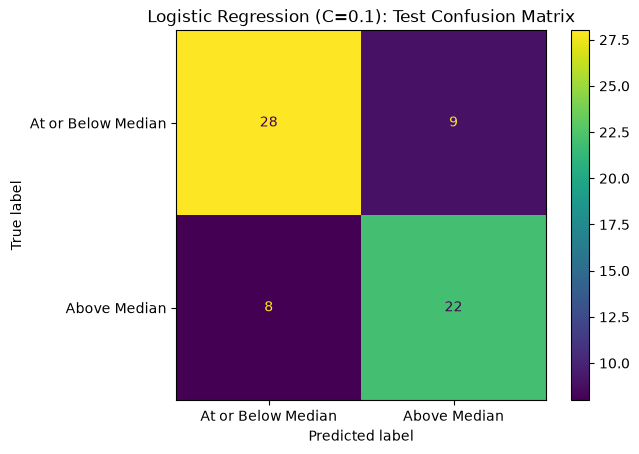

In [29]:
cm = confusion_matrix(
    y_test_class,
    test_pred_logistic,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["At or Below Median", "Above Median"]
)

disp.plot()
plt.title(f"{best_logistic_name}: Test Confusion Matrix")
plt.show()

### Logistic Regression Model Comparison and Selection

The two logistic regression classifiers use different regularization strengths (`C=0.1` and `C=10`). **C = 0.1 was selected** because it had the higher validation F1-score (**0.844**, compared with **0.826** for C = 10). The selected model's test F1-score was **0.721**, with test accuracy **0.746**, precision **0.710**, and recall **0.733**. The gap between validation and test F1 indicates that the validation score was an optimistic estimate for this particular split. Because the target was converted into binary classes using the training median, this remains a separate classification experiment rather than a direct substitute for predicting the original continuous target.

## Overall Conclusion

This lab compared a univariate BMI polynomial model with multivariate polynomial regression, decision-tree regression, kNN regression, and a separate logistic-regression classification experiment.

For continuous disease-progression prediction, the consolidated comparison table shows the following selected models and test results:

- **Multivariate polynomial, degree 2:** test R² = **0.337**, MAE = **45.867**, MAPE = **39.474%**. It had the lowest test MAE among the three selected multivariate regression models.
- **Decision tree, depth 3:** test R² = **0.308**, MAE = **50.371**, MAPE = **44.903%**.
- **kNN, k = 10:** test R² = **0.377**, MAE = **46.939**, MAPE = **41.588%**. It had the highest test R² among these three models.

Thus, **kNN had the highest test R², while the degree 2 polynomial had the lowest test MAE**. The best choice depends on the metric and the purpose of the analysis; none of the models should be described as highly accurate based on these results. The BMI-only degree 3 model performed less well on the test set (R² = 0.207, MAE = 54.629, MAPE = 48.54%), supporting the value of using multiple features.

**Where the models fail and limitations**
- The models leave substantial variation unexplained, and their MAE values indicate meaningful errors in the target's units.
- MAPE can give disproportionate weight to observations with smaller actual target values, so it should not be interpreted alone.
- The multivariate degree 3 polynomial had much lower training error but dramatically worse validation error than degree 2, a clear warning sign of poor generalization. The depth 5 tree also performed worse on validation than the depth 3 tree.
- The dataset is relatively small and uses scaled predictors. Results depend on this particular train/validation/test split and may not generalize to other populations or clinical settings.
- Logistic regression predicts a binary category defined by the training median (142.0), not the original continuous progression score. Its test accuracy was 0.746 and test F1 was 0.721; these classification metrics are reported separately and are not directly comparable with regression metrics.

**Workshop connections.** The Performance Metrics workshop emphasizes using multiple metrics. The kNN workshop highlights scaling and the effect of hyperparameters on generalization. The Logistic Regression workshop reinforces that classification requires a categorical target. Across the regression models, validation MAE guides model selection and the held-out test set is used for final evaluation. This notebook is an educational analysis, not a clinical screening or diagnostic tool.